<a href="https://colab.research.google.com/github/MatthiasVanW/ISYS2001-Assessment-2-Programming-Assignment-Matthias-Vanwolleghem/blob/main/ISYS2001_Programming_Assignment_Matthias_Vanwolleghem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart finance assistant: personal spending analyser
**Course**: ISYS2001 Introduction to Business Programming  
**Author**: Matthias Vanwolleghem  
**Project**: Assessment 2: Programming Assignment
____________________

## Six-Step Method

### Step 1: understanding the problem
When I look at my own spending reports, I notice they are often messy or hard to understand. This makes it frustrating to see where my money actually goes each month.

To solve this problem, I'm designing and building my own personal spending analyser. My goal is to create a simple tool that helps me to know where my money is going and how I can spend smarter.

To achieve this, my application will:
1. Safely load and clean raw CSV transaction files that I upload.
2. Run my own custom analytical logic to calculate category totals, spending percentages and identify my biggest expenses.
3. Include my own self-conceived feature that converts my spending totals into the equivalent number of beers (assuming $10 per beer).
4. Pass my clean financial numbers as context to a personal AI finance coach powered by Gemini, so it can give me direct data-driven advice instead of generic tips
5. Put a clear interactive Gradio interface so I can upload files and chat with my assistant without looking at the Python code.

----------

### Step 2: dentify inputs and outputs

* **Inputs**:
  * A CSV file I upload containing my transaction records ('Category', 'Amount' and 'Date')
  * Questions or prompts I type into the chat interface.

* **Outputs**:
  * A clean summary showing how much I spent per category.
  * Key figures like: my total spend, top spending category, spending percentages and my total spend expressed in number of beers.
  * Personalised data-driven financial advice from Gemini based on my actual numbers.

----------

### Step 3: worked example by hand

To test my logic I'll work throug a small fictive example.

Suppose I upload a CSV with these rows:
- `Date`: 2026-10-01, `Category`: Groceries, `Amount`: "\$50.00"
- `Date`: 2026-10-02, `Category`: Groceries, `Amount`: "\$30.00"
- `Date`: 2026-10-03, `Category`: Entertainment, `Amount`: "\$20.00"

1. **Clean**: I strip the `$` signs and change the values to float numbers: `[50.0, 30.0, 20.0]`.
2. **Group & aggregate**:
  - **Groceries**: \$50.00 + $30.00 = \$80.00 (80% of my spendings; equivalent to 2 beers at \$10 each)
  - **Entertainment**: \$20.00 (20% of my spend; equivalent to 8 beers at \$10 each)
3. **Total spend**: \$80.00 + \$20.00 = \$100.00
4. **Context for AI**: I feed this clean summary to Gemini: `"Total spent: $100.00 (10 beers). Top category: Groceries ($80.00 / 8 beers). How can I trim this?"`

----------

### Step 4: pseudocode

```text
CLASS Transaction:
    PROPERTIES: date, category, amount

CLASS FinanceManager:
    CONSTRUCTOR:
        INITIALISE empty transactions list
        SET BEER_PRICE = 10.00

    METHOD load_from_csv(file_input):
        TRY:
            LOAD CSV into DataFrame
            CLEAN column names (strip whitespace, standardise capitalisation)
            CHECK for required columns ('Category', 'Amount')
            IF missing:
                RETURN clear error message to user
            CLEAN 'Amount' column (strip '$', convert to float)
            CONVERT valid rows into Transaction objects
            RETURN success message
        EXCEPT Exception as e:
            RETURN clear user error message

    METHOD analyze_spending():
        IF transactions list is empty:
            RETURN warning message
        CONVERT transactions to DataFrame
        GROUP BY 'Category' and SUM 'Amount'
        CALCULATE total spend and percentage per category
        CALCULATE beer_equivalent = total_spend / 10.00
        IDENTIFY top category and highest spend
        RETURN summary text (including beer metric) and formatted summary DataFrame

FUNCTION ask_financial_coach(user_query, spending_summary):
    CONFIGURE Gemini API with system instruction ("You are an empathetic financial coach...")
    COMBINE spending_summary + user_query into full prompt
    CALL Gemini API (gemini-3.8-flash)
    RETURN AI response
```

----------


## Gemini API connection test
(This setup and verification code was generated with AI assistance.)

I want to verify that the Google Gemini API key is properly configured and accessible via Google Colab Secrets (`GEMINI_API_KEY`), before I run my code.

The code block below retrieves the secure key using `google.colab.userdata` and performs a minimal call to the `gemini-3.8-flash` model to confirm successful authentication.

Disclaimer / Note: The connection to the Gemini API may occasionally time out or fail on the first try due to temporary high server usage or rate limits. If an error occurs, simply re-run this code cell once or twice until a successful response is returned or just wait for a bit.

**MORE IMPORTANT DISCLAIMER:** The free tier for `gemini-3.8-flash` has a strict daily rate limit of 20 API calls per day. Avoid re-running this verification cell unnecessarily so you do not exhaust your daily quota while testing the rest of the application.

In [1]:
# Here I just asked AI to help me because I wanted to be sure that my Key was correctly installed

# 1. Installing and importing required libraries
!pip install -q google-genai

import os
from google import genai
from google.colab import userdata

# 2. Retrieve the API key from Colab Secrets
try:
    api_key = userdata.get('GEMINI_API_KEY')
    client = genai.Client(api_key=api_key)

    # 3. Send a test query using gemini-3.8-flash
    response = client.models.generate_content(
        model='gemini-3.8-flash',
        contents='Hello, please confirm in a single short sentence that you have established the connection to the ISYS2001 project.'
    )

    print(" SUCCESS: Gemini API connection established!")
    print("Response from Gemini:\n", response.text)

except Exception as e:
    err_str = str(e)
    if "429" in err_str or "quota" in err_str.lower():
        print(" ⚠️ API KEY IS VALID, BUT DAILY QUOTA EXCEEDED (HTTP 429).")
        print("The API key was successfully read from Colab Secrets, but the free-tier daily limit for gemini-3.8-flash was reached. Please wait for the daily quota to reset or re-run later.")
    else:
        print(" ERROR: Could not connect to Gemini API.")
        print("Details:", e)

 SUCCESS: Gemini API connection established!
Response from Gemini:
 I confirm that the connection to the ISYS2001 project has been established.



### Step 5: convert pseudocode to code


In [13]:
class Transaction:
    """Represents an individual financial transaction."""

    def __init__(self, date: str, category: str, amount: float, description: str = ""):
#store essential details for a single expense
        self.date = date
        self.category = category
        self.amount = amount
        self.description = description

    def __repr__(self):
#clean formatting for displaying object information
        return f"Transaction({self.date}, {self.category}, ${self.amount:.2f})"

import pandas as pd

class FinanceManager:
    """Manages transaction records, data cleaning and custom analytics."""

    def __init__(self, beer_price: float = 10.0):
#list to hold Transaction objects and standard beer conversion cost
        self.transactions = []
        self.beer_price = beer_price

    def load_from_dataframe(self, df: pd.DataFrame):
        """Cleans raw DataFrame input and converts rows into Transaction objects."""

#standardise column headers (remove whitespaces and lowercase)
        df.columns = df.columns.str.strip().str.lower()

#check for mandatory columns
        required_cols = {'date', 'category', 'amount'}
        if not required_cols.issubset(df.columns):
            raise ValueError(f"CSV must contain columns: {required_cols}")

        self.transactions = []
        for _, row in df.iterrows():

#check for missing/NaN amount to prevent 'nan' totals
            if pd.isna(row['amount']):
                continue

#clean currency symbols ($) and convert text to float
            raw_amount = str(row['amount']).replace('$', '').replace(',', '.').strip()
            try:
                clean_amount = float(raw_amount)
            except ValueError:
                continue

#clean and standardise date formats (ex 1/10/2026 to 2026-10-01) Done with AI after failed tests
            raw_date = str(row['date']).strip()
            try:
                clean_date = pd.to_datetime(raw_date, dayfirst=True).strftime('%Y-%d-%m')
            except Exception:
                clean_date = raw_date  # Fallback to raw string if parsing fails

#clean category and handle missing/NaN categories
            raw_cat = row['category']
            if pd.isna(raw_cat) or str(raw_cat).strip() == '':
                clean_cat = 'Uncategorized'
            else:
                clean_cat = str(raw_cat).strip().title()

#clean description
            desc = row.get('description', '')
            if pd.isna(desc):
                desc = ''

#create a Transaction instance per row
            t = Transaction(
                date=clean_date,
                category=str(row['category']).strip().title(),
                amount=clean_amount,
                description=str(desc)
            )
            self.transactions.append(t)

    def calculate_totals_by_category(self) -> dict:
        """Aggregates total spending grouped by category."""
        category_totals = {}

#sum up amounts per unique category
        for t in self.transactions:
            category_totals[t.category] = category_totals.get(t.category, 0.0) + t.amount
        return category_totals

    def get_summary_report(self) -> dict:
        """Generates comprehensive expenditure summary and custom analytics."""
#safety check for empty transaction list
        if not self.transactions:
            return {"error": "No valid transactions loaded."}

        total_spent = sum(t.amount for t in self.transactions)
        cat_totals = self.calculate_totals_by_category()

#calculate percentages per cat
        cat_percentages = {
            cat: round((amt / total_spent) * 100, 1)
            for cat, amt in cat_totals.items()
        } if total_spent > 0 else {}

#identifie top 3 largest expenses
        sorted_transactions = sorted(self.transactions, key=lambda t: t.amount, reverse=True)
        top_expenses = [
            {"date": t.date, "category": t.category, "amount": t.amount, "description": t.description}
            for t in sorted_transactions[:3]
        ]
#custom beer converter
        beers_equivalent = total_spent / self.beer_price if self.beer_price > 0 else 0

        return {
            "total_spending": round(total_spent, 2),
            "category_breakdown": {cat: round(amt, 2) for cat, amt in cat_totals.items()},
            "category_percentages": cat_percentages,
            "top_expenses": top_expenses,
            "total_beers_equivalent": round(beers_equivalent, 1),
            "transaction_count": len(self.transactions)
        }

Now I'll test the `Transaction` and `FinanceManager` classes using a small made up sample dataset to verify that everything works as expected.

In this test I check:
- Whether the `$` symbols are properly removed and amounts are converted into numeric values.
- Whether category breakdowns, percentages, top expenses and the beer converter gets calculated correctly.
- Whether the Gemini API reads the summary properly and returns useful budget coaching

In [14]:
!pip install -q google-genai

import pandas as pd
from google.colab import userdata
from google import genai

#create sample test data with messy input
test_data = {
    'Date': ['2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04'],
    'Category': [' Groceries ', 'Entertainment', 'Groceries', 'Tech'],
    'Amount': ['$45.50', '20.00', '$34.50', '$120.00'],
    'Description': ['Weekly food', 'Movie ticket', 'Snacks', 'New Headphones']
}
df_test = pd.DataFrame(test_data)

#test FinanceManager analytics
manager = FinanceManager(beer_price=10.0)
manager.load_from_dataframe(df_test)
summary = manager.get_summary_report()

print("--- ANALYTICS REPORT ---")
print(f"Total Spent: ${summary['total_spending']}")
print(f"Category Percentages: {summary['category_percentages']}")
print(f"Top Expense: {summary['top_expenses'][0]}")
print(f"Beer Equivalent ($10/beer): {summary['total_beers_equivalent']} beers")

#test Gemini API integration
try:
    api_key = userdata.get('GEMINI_API_KEY')
    client = genai.Client(api_key=api_key)

    prompt = f"""
    You are a friendly and constructive AI Financial Coach.
    Analyse this spending summary:
    - Total Spent: ${summary['total_spending']}
    - Category Percentages: {summary['category_percentages']}
    - Top Expenses: {summary['top_expenses']}
    - Total Beers Equivalent ($10/beer): {summary['total_beers_equivalent']} beers

    Provide 2 short budgeting tips. Include a lighthearted reference to their spending converted into beers.
    """

    response = client.models.generate_content(
        model='gemini-3.8-flash',
        contents=prompt
    )
    print("\n--- GEMINI AI COACH ADVICE ---")
    print(response.text)

except Exception as e:
    print("\n AI Coach error or limit reached:", e)

--- ANALYTICS REPORT ---
Total Spent: $220.0
Category Percentages: {'Groceries': 36.4, 'Entertainment': 9.1, 'Tech': 54.5}
Top Expense: {'date': '2026-10-04', 'category': 'Tech', 'amount': 120.0, 'description': 'New Headphones'}
Beer Equivalent ($10/beer): 22.0 beers

 AI Coach error or limit reached: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 17h41m23.306995682s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, 

In [4]:
!pip install -q gradio

Below is going to be the Gradio application that allows to upload a CSV file, view cleaned financial analytics and receive automated financial coaching from Gemini.

In [ ]:
!pip install -q google-genai

import gradio as gr
import pandas as pd
from google.colab import userdata
from google import genai

#copied from earlier
try:
    api_key = userdata.get('GEMINI_API_KEY')
    client = genai.Client(api_key=api_key)
except Exception as e:
    print(f"Warning: Could not configure Gemini API Key. Details: {e}")

def process_and_coach(file_obj, beer_price: float = 10.0):
    """
    Processes the uploaded CSV file using FinanceManager,
    calculates analytics and calls Gemini AI for financial coaching.
    """
    if file_obj is None:
        return "Please upload a CSV file.", "", "", ""

#safe fallback if user inputs 0 or a negative price
    if beer_price < 0:
        beer_price = abs(beer_price)

    try:
  #loading CSV into DataFrame
        df_raw = pd.read_csv(file_obj.name, sep=None, engine='python')

  #FinanceManager processing
        manager = FinanceManager(beer_price=beer_price)
        manager.load_from_dataframe(df_raw)
        summary = manager.get_summary_report()

        if "error" in summary:
            return f"Error: {summary['error']}", "", "", ""

  #key metrics for display
        metrics_text = (
            f" **Total Spending:** ${summary['total_spending']:.2f}\n"
            f" **Total Transactions:** {summary['transaction_count']}\n"
            f" **Beer Converter (${beer_price:.0f}/beer):** {summary['total_beers_equivalent']} beers"
        )

  #format category breakdown
        category_lines = []
        for cat, amt in summary['category_breakdown'].items():
            pct = summary['category_percentages'].get(cat, 0.0)
            category_lines.append(f"- **{cat}:** ${amt:.2f} ({pct}%)")
        category_text = "\n".join(category_lines)

  #format top expenses
        top_lines = []
        for idx, exp in enumerate(summary['top_expenses'], 1):
            top_lines.append(f"{idx}. **{exp['category']}**: ${exp['amount']:.2f} ({exp['description']}) on {exp['date']}")
        top_text = "\n".join(top_lines)

  #generate Gemini AI Financial Advice
        try:
            prompt = f"""
            You are a friendly, humorous and practical AI Financial Coach.
            Analyse this user spending summary:
            - Total Spent: ${summary['total_spending']}
            - Category Percentages: {summary['category_percentages']}
            - Top Expenses: {summary['top_expenses']}
            - Total Beers Equivalent (${beer_price:.0f}/beer): {summary['total_beers_equivalent']} beers

            Provide 2-3 short, actionable budgeting tips. Make a witty reference to their spending
            converted into beers to keep it engaging and realistic.
            """
            response = client.models.generate_content(
                model='gemini-3.8-flash',
                contents=prompt
            )
            ai_advice = response.text
        except Exception as api_err:
            ai_advice = (
                "**AI Coach temporarily unavailable (Rate Limit / Quota Exceeded: 20 calls/day)**\n\n"
                f"*Details: {str(api_err)}*\n\n"
                "**Offline Fallback:** Your core financial metrics above were calculated successfully! "
                "Consider setting a spending cap on your top expense categories."
            )

        return metrics_text, category_text, top_text, ai_advice

    except Exception as err:
        return f"An error occurred while processing the file: {str(err)}", "", "", ""

#create Gradio Blocks UI
with gr.Blocks(theme=gr.themes.Soft(), title="AI Financial Manager & Coach") as demo:
    gr.Markdown("# Personal Finance Manager & AI Coach")
    gr.Markdown("Upload your transaction CSV file below to get automated analytics and personalized AI financial advice.")

    with gr.Row():
        with gr.Column():
            file_input = gr.File(label="Upload CSV Transactions", file_types=[".csv"])
            beer_price_input = gr.Number(label="Beer Benchmark Price ($)", value=10.0, precision=2)
            btn = gr.Button("Analyze & Get AI Advice", variant="primary")

        with gr.Column():
            metrics_output = gr.Markdown(label="Key Metrics")
            category_output = gr.Markdown(label="Category Breakdown")
            top_output = gr.Markdown(label="Top Expenses")

    gr.Markdown("---")
    gr.Markdown("### Gemini AI Financial Coach Advice")
    ai_output = gr.Markdown()

    btn.click(
        fn=process_and_coach,
        inputs=[file_input, beer_price_input],
        outputs=[metrics_output, category_output, top_output, ai_output]
    )

#launch the interactive interface inside Colab
demo.launch(share=True, debug=True)

/tmp/ipykernel_2524/3772080139.py:91: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="AI Financial Manager & Coach") as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://da5863e408271290d8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Step 6: Testing


#### 1. **Date Formatting Consistency:**

During testing with raw CSV files exported directly from Excel (European regional settings), I found the following problem:
   * *Issue:* Excel exports dates in regional format `DD/MM/YYYY` (e.g., `1/10/2026`).
   * *Test:* Verified using `pd.to_datetime(raw_date, dayfirst=True)` to ensure standardisation to ISO format `YYYY-MM-DD` (`2026-10-01`).   

old code: non existent

new: #clean and standardise date formats (ex 1/10/2026 to 2026-10-01) Done with AI after failed tests
            raw_date = str(row['date']).strip()
            try:
                clean_date = pd.to_datetime(raw_date, dayfirst=True).strftime('%Y-%m-%d')
            except Exception:
                clean_date = raw_date  # Fallback to raw string if parsing fails   


#### 2. **Decimal & Separator Compatibility:**

I also stumbled on this problem while testing with raw CSV files exporte from my Excel:
   * *Issue:* European Excel uses commas for decimals (`$45,50`) and semicolons (`;`) for CSV columns.
   * *Test:* Verified that `sep=None` auto-detects column separators and `.replace(',', '.')` safely converts values into standard floats.

old:         df_raw = pd.read_csv(file_obj.name)

new:         df_raw = pd.read_csv(file_obj.name, sep=None, engine='python')


## PROOF OF 1 and 2

**Before fixing**

Transactions with comma decimals such as $45,50 were not recognized and were  skipped during ingestion. Because these transactions were missing, the total spending calculations, beer converter and top 3 expenses were completely inaccurate. Additionally, regional dates like 1/10/2026 were not converted, resulting in missing dates and sorting errors throughout the output.

**After fixing**

As you can see in the screenshots, every transaction is being ingested and the dates are also converted into YY-DD-MM.



Test database:

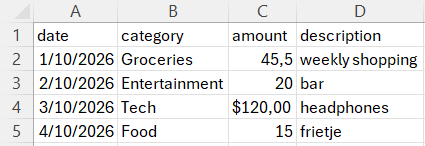


result:

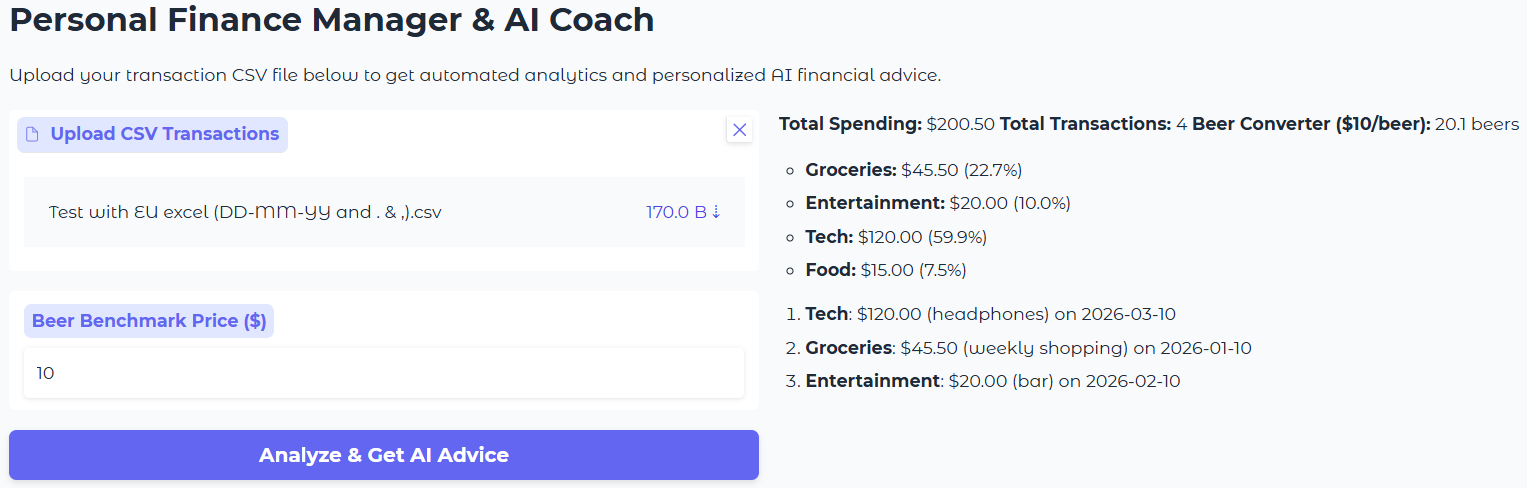

#### 3. **API Limit**

During the  testing phase of Step 6, I discoverd an API usage limit was  through extensive trial-and-error:

* Discovery: The free tier for the `gemini-3.8-flash` model enforces a strict rate limit of 20 API calls per day.
* Evaluation & Workaround: I searched for potential  workarounds. However, I didn't find a free solution to this problem. Instead, I concluded that a standard user will naturally stay well under 20 transactions/calls per day.



#### 4. **Missing data in dataset**

**Before fixing**

When ingesting a CSV with missing fields (ex. empty category or missing amount), Pandas parses missing values as NaN. This causes the total sum, beer converter and percentages to result in nan or 0.0%.

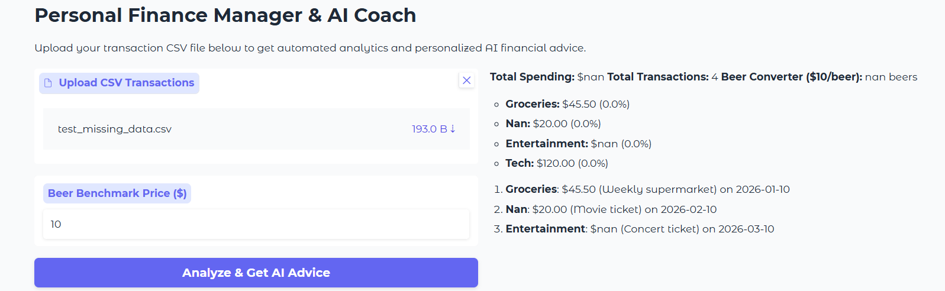




**Fix in code and after**


check for missing/NaN amount to prevent 'nan' totals

            if pd.isna(row['amount']):
                continue


clean category and handle missing/NaN categories

            raw_cat = row['category']
            if pd.isna(raw_cat) or str(raw_cat).strip() == '':
                clean_cat = 'Uncategorized'
            else:
                clean_cat = str(raw_cat).strip().title()


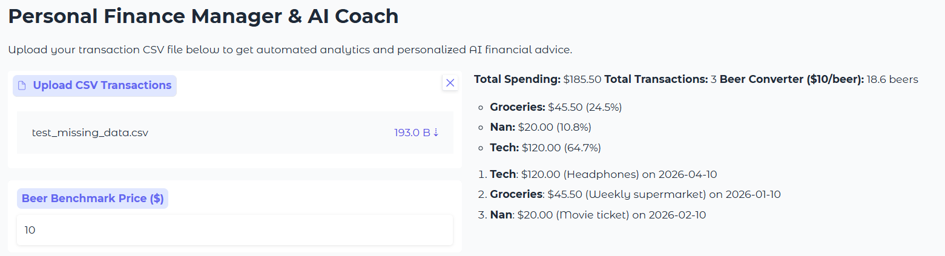


#### 5. **Extra columns in dataset**

I used this dataset:

```
Transaction_ID,Date,Account_IBAN,Category,Amount,Currency,Description,Status
1001,2026-10-01,BE123456789,Groceries,45.50,EUR,Supermarket,Completed
1002,2026-10-02,BE123456789,Entertainment,15.00,EUR,Cinema,Completed
1003,2026-10-03,BE123456789,Transport,25.00,EUR,Gas Station,Pending
```

And this was the result:

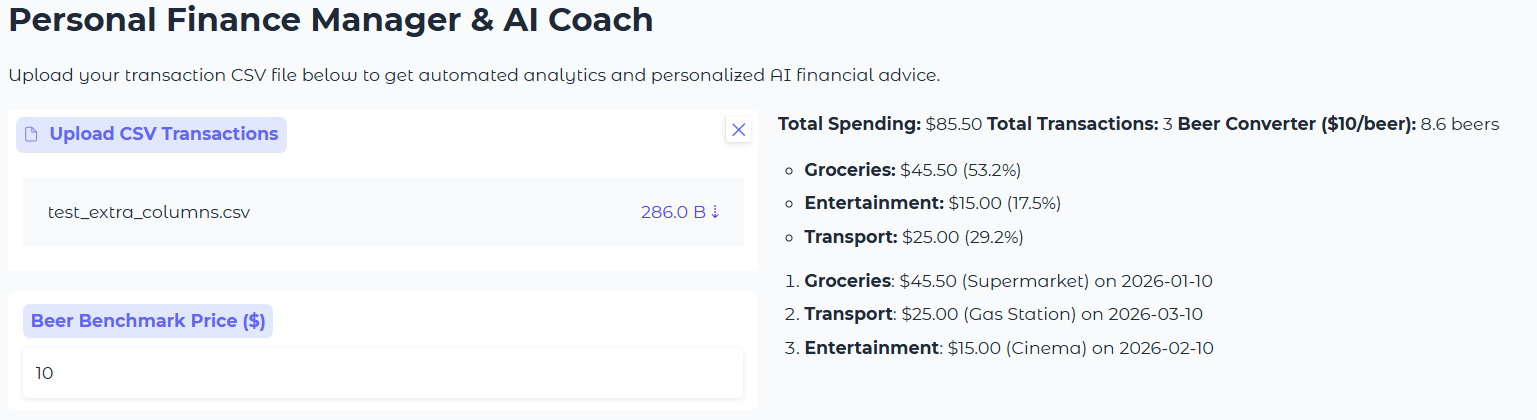

As you can see it didn't form any problems.

#### 6. **Extreme small or large datasets**

A) small datasets

Used data set:

```
Date,Category,Amount,Description
2026-10-01,Groceries,50.00,Single Supermarket Trip
```

Result:

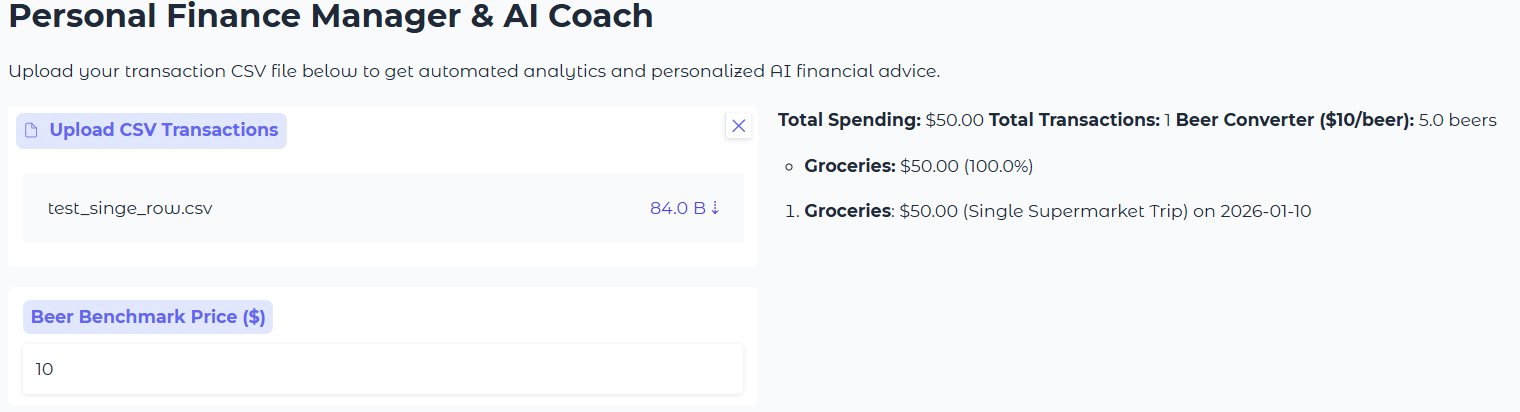

As you can see, no problems with a single row dataset

B) large datasets

For this test, I created a dataset of 50 transactions and duplicated the entries sequentially until reaching 1000 rows.


How can I proof that all transactions were processed without any lost rows or errors?

In the original 50-row dataset, the highest single expense was Monthly Apartment Rent at \$950. When scaled up to 1000 rows (a 20x repetition), the total amount for the categroy Rent in the UI shows exactly \$19,000 (\$950 × 20). This mathematically proves that all 1,000 transactions were processed without any lost rows or errors.

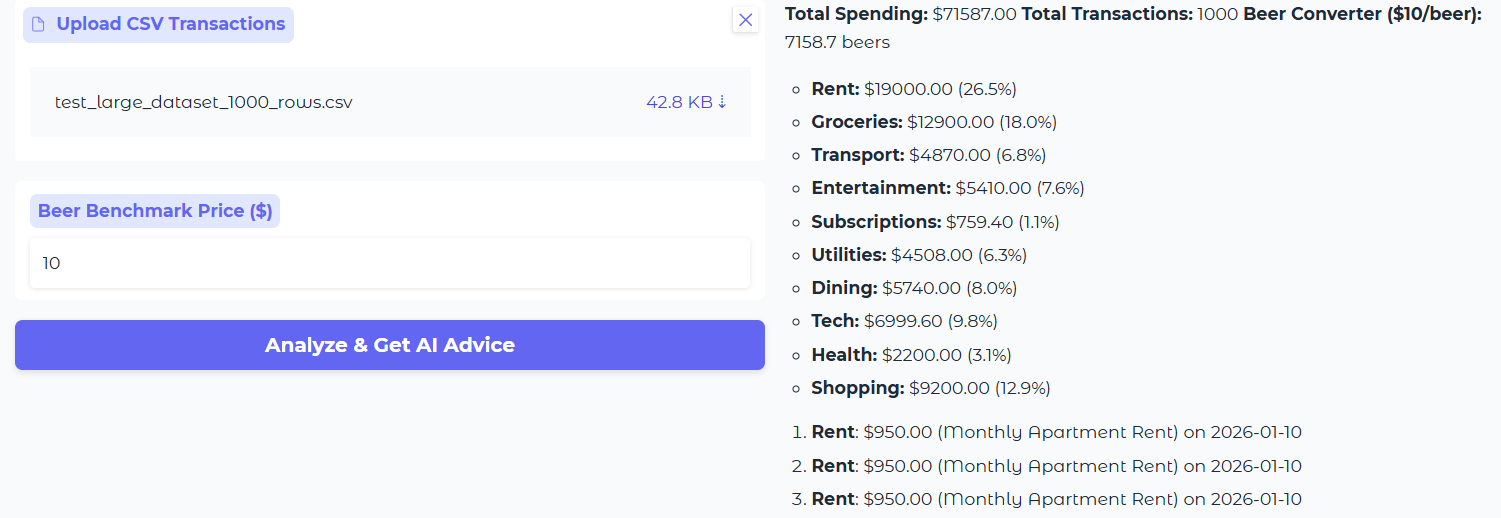



#### 7. **Invalid input**

When uploading a non-CSV file format such as a `.txt` file, the Gradio interface shows the following  error message:

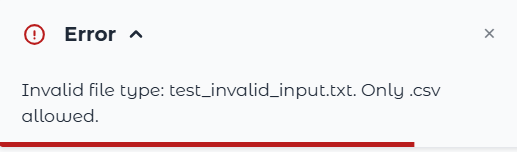



#### 8. **Edge cases of custom beer price (ex. 0 and -5)**

During testing with custom beer benchmark prices, I identified a minor UI inconsistency. The total beer calculation updated correctly, but the label in the output header remained fixed at `($10/beer)`.

Code Improvement:
To ensure the output label dynamically reflects the user's input, I updated the string formatting in the UI function:

```
# Updated dynamic header line
f" **Beer Converter (${beer_price:.0f}/beer):** {summary['total_beers_equivalent']} beers"

# Updated prompt sent to Gemini AI
f"- Total Beers Equivalent (${beer_price:.0f}/beer): {summary['total_beers_equivalent']} beers"
```

Initial edge-case testing with \$0 or negative values (ex. -5) exposed failures: \$0 risked an error and  negative prices gave illogical labels like (\$-5/beer). To solve this, I added this extra code:

```
#safe fallback if user inputs 0 or a negative price
    if beer_price < 0:
        beer_price = abs(beer_price)
```

Now, \$0 explicitly outputs 0 beers (\$0/beer) without crashing and negative inputs automatically apply abs() assuming an accidental typo, guaranteeing logical metrics.


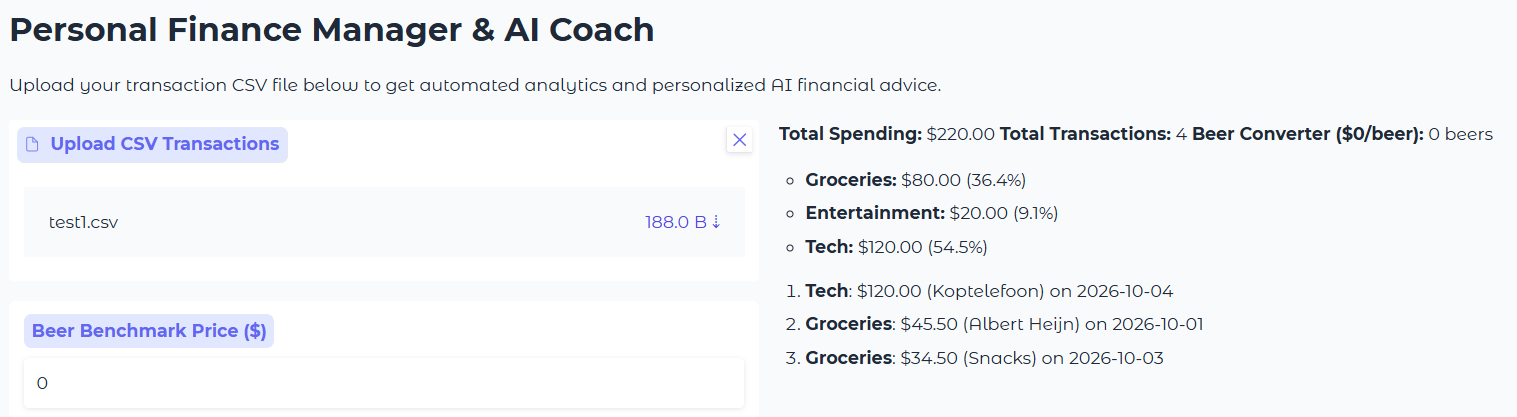

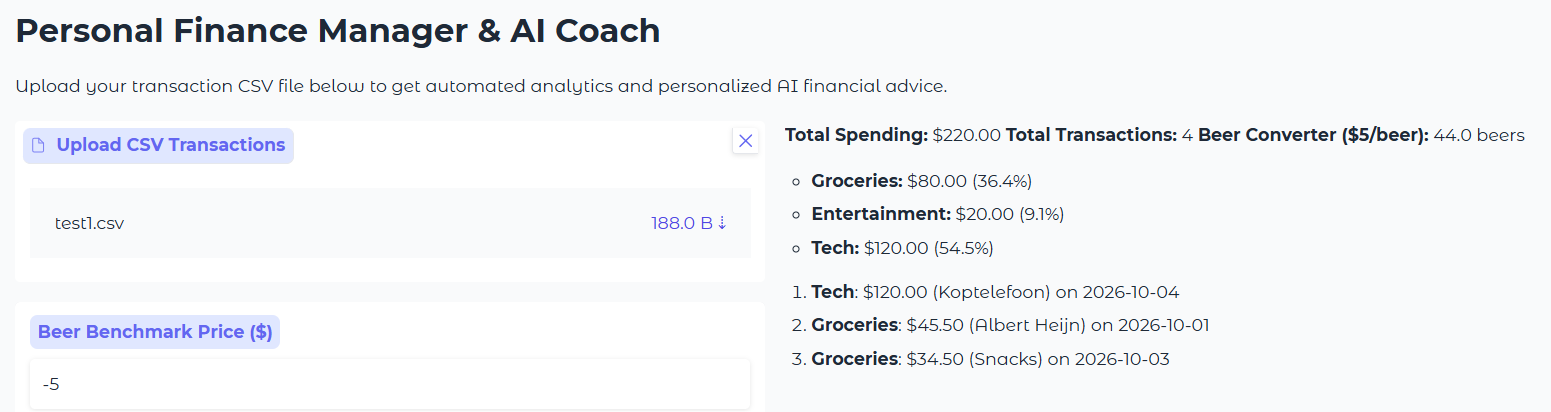